In [47]:
# Importing Libraries
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt

# Loading Data
dataset = load_dataset("lukebarousse/data_jobs")
df = dataset["train"].to_pandas()

# Data Cleanup
df["job_posted_date"] = pd.to_datetime(df["job_posted_date"])

In [97]:
df_US = df[df['job_country'] == 'United States'].copy()

In [98]:
df_jobs

,job_id,company_name
0,1,Google
1,2,Microsoft
2,3,Apple
3,4,Meta
4,5,Starbucks


In [99]:
df_companies

,company_name,industry,company_size
0,Google,Technology,100000
1,Microsoft,Technology,200000
2,Apple,Technology,100000
3,Meta,Technology,75000
4,Starbucks,Food & Beverage,349000


In [100]:
df_jobs.merge(df_companies, on='company_name')

,job_id,company_name,industry,company_size
0,1,Google,Technology,100000
1,2,Microsoft,Technology,200000
2,3,Apple,Technology,100000
3,4,Meta,Technology,75000
4,5,Starbucks,Food & Beverage,349000


In [101]:
df_US = df[df['job_country'] == 'United States'].copy()

df_US['job_posted_month'] = df_US['job_posted_date'].dt.strftime('%B')

df_US_pivot = df_US.pivot_table(index='job_posted_month', columns='job_title_short', aggfunc='size')

df_US_pivot = df_US_pivot.reset_index()

df_US_pivot['job_posted_month_no'] = pd.to_datetime(df_US_pivot['job_posted_month'], format='%B').dt.month

df_US_pivot = df_US_pivot.sort_values('job_posted_month_no')

df_US_pivot = df_US_pivot.set_index('job_posted_month')

df_US_pivot = df_US_pivot.drop(columns='job_posted_month_no')

df_US_pivot

job_title_short,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer
job_posted_month,,,,,,,,,,
January,527,36,8494,2655,6915,60,1544,773,1552,114
February,447,24,6124,3060,4956,56,1258,878,1127,90
March,438,19,6218,3183,4779,59,1114,829,1150,115
April,565,40,6049,2801,4867,51,1025,781,991,112
May,279,20,4993,2976,4377,49,839,746,914,90
June,446,32,5683,2893,4645,48,1009,812,1033,93
July,581,39,5201,2570,4876,65,883,747,1095,153
August,903,39,6634,3269,6318,68,1186,903,1515,194
September,897,50,4639,3224,4568,113,805,775,1014,228


In [105]:
df_US_software_pivot = pd.read_csv("https://lukeb.co/software_csv", index_col='job_posted_month')

df_US_software_pivot

,Front-End Developer,Back-End Developer,Full-Stack Developer,UI/UX Designer
job_posted_month,,,,
January,13619,9827,5108,4348
February,11456,9116,7298,4284
March,11102,8178,5814,4159
April,14037,9209,7232,4220
May,12126,8864,6718,4980
June,12003,8065,5902,4781
July,11914,8061,6839,4344
August,11571,8191,7413,4104
September,14016,8447,6139,4094


In [107]:
df_US_merged = df_US_pivot.merge(df_US_software_pivot, on="job_posted_month")

In [111]:
top_5 = (
    df_US_merged
    .sum()
    .sort_values(ascending=False)
    .head()
    .index #Get the index of the top 5
    .to_list()
)

top_5

['Front-End Developer',
 'Back-End Developer',
 'Full-Stack Developer',
 'Data Analyst',
 'Data Scientist']

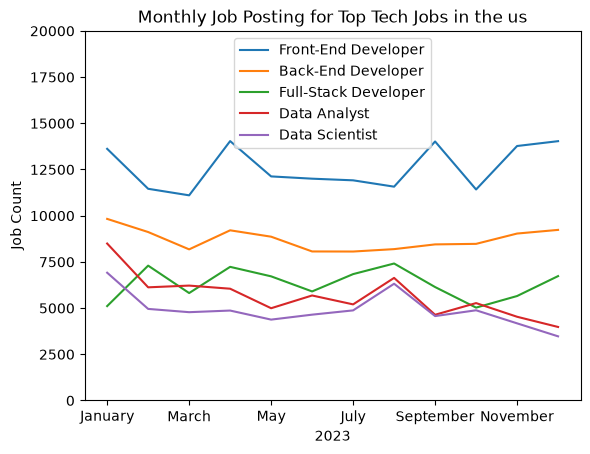

In [114]:
df_US_merged[top_5].plot(kind='line')

plt.title('Monthly Job Posting for Top Tech Jobs in the us')
plt.xlabel('2023')
plt.ylabel('Job Count')
plt.ylim(0, 20000)
plt.legend()
plt.show()